# New section

# KNN

Classification problems seek to predict the "class" of a particular data point, for instance, if an email is spam or not, or if a breast cancer tumour is malignant or benign. In these examples there are only 2 classes, so it's a more specfic problem: binary classification.

How do we approach this? This is a supervised learning problem, so we have a bunch of labelled data points, which I imagine have been plotted on a graph. Given a new data point, what do I predict the label to be? The simplest first idea is to simply look at the nearest point, and give its label as the prediction.

This is not a bad idea, but it will be very sensitive to outliers: if the test data point just happened to land near a single outlier, we would assign it the unlikely label. To counter this, we instead take the k nearest neighbours, and pick the majority label among them. The number of neighbours in KNN is a hyperparamter that needs to be tuned with CV.

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

X, y = load_breast_cancer(as_frame=True, return_X_y=True)
X_train, X_test, y_train, y_test  = train_test_split(X, y, test_size=0.2, random_state=42)

knn = Pipeline([("feature_scaling", StandardScaler()), ("knn" , KNeighborsClassifier())])
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



# Decision Trees

KNN is a very silly "ML" algorithm, because it doesn't really learn any model from the data. It needs to retain the entire dataset and check against it for each test case.

The power of ML models actually arises from assuming a model about the data. Why? Well, if you studied for a physics test, and got quizzed on history, you would not perform well. How is the training data even supposed to help you? No model can perform well in that setting. The only situation where we can expect results is if there is some underlying commonality between the test and train data, that is, the data itself follows some underlying model or set of rules in being created.

We will model the generative process itself soon, but I'd like to discuss another basic idea: Decision trees. In the breast cancer dataset, maybe it so happens that every tumour above a certain radius is assuredly malignant. Maybe, if you ask a few questions: is age > x, is blood pressure > y etc. you can narrow down the data into a few buckets, where we know that the overwhelming amount of data says that the tumour belongs to one class or the other. This is a popular algorithm, not only because of the success it sees in many applications, but because of how highly interpretable the results are; A doctor would feel a bit more confident with the reasoning of criteria used to classify than a magic black box that spits out a classification.

1. What kind of questions do you ask ?

Ans: We constrain ourselves to "Is feature $x_i \le$ threshold $t$?"

2. How many questions do you ask?

Ans: This is a hyperparameter to be tuned; if we ask too many and we narrow down to one or two data points, we would have horrifically overfit, and the model would lose all meaning.

3. How do you determine which question to ask? What is the measure of the goodness of a question?

Ans: There are many answers to this. The one I'm most familiar with is an information theoretic metric called mutual information.


## Entropy


Entropy is essentially information. Information is information we know, and entropy is information we don't know. If there is a coin that always tosses heads, like at the start of _the dark night_, then it has no entropy; there is no information we don't know about the result of its toss. Halfway through the movie though, the entropy of the system goes up, and it gains 1 bit of entropy (That is you need to ask one question to know everthing about the system).

Consider a system that produces label 1 to 4 with probabilities 0.5,0.25,0.125 and 0.125. You need to first ask "is the label 1?", and 50% of the time, you'll be done there. Else, you then ask, "is it 2?" and so on. Overall, since 2 occurs 25% of the time, you will need 2 questions, 25% of the time.

More broadly, if an event occurs 1 in 64 times, to isolate the event, you need to keep dividing the sample space by 2 with each question till you get 1, that is you need $\log_2(64)$ questions. In general, if an event occurs with probability $p$, to narrow down its occurence, you'll need $\log_2(\frac{1}{p})$ questions.

$$ \mathbb{E}[n_{questions}] = \sum_i p_i \cdot \log_2(\frac{1}{p_i}) $$

$$ H := - \sum_i p_i \cdot \log_2(p_i) $$

This quantity is entropy. If a set of numbers all have the same label, example, heads, then it has no information left. In a decision tree, after we pose a question, if the subsets remaining have lost a lot of information they had before, we made a good question. That is, we define goodness as the information gain: if a set $X$ was divided into $X_{yes}$ and $X_{no}$, by the random variable $Q$ (for question) the information gain is given by:

$$ H(X) - H(X|Q) = H(X) - [p_{yes}\cdot H(X_{yes}) + p_{no} \cdot H(X_{no})]$$

Having now defined the goodness of a question, Decision trees pick the question with greatest information gain by trying out as many questions as possible. This is done by suitably discretising the space of each parameters, evenly dividing it, and trying all the values.



In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text

dt_clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
dt_clf.fit(X_train, y_train)

y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))

# Print the actual tree — see which questions it learned to ask
print(export_text(dt_clf, feature_names=list(X.columns)))

              precision    recall  f1-score   support

           0       1.00      0.91      0.95        43
           1       0.95      1.00      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

|--- mean concave points <= 0.05
|   |--- worst radius <= 16.83
|   |   |--- area error <= 48.70
|   |   |   |--- class: 1
|   |   |--- area error >  48.70
|   |   |   |--- class: 0
|   |--- worst radius >  16.83
|   |   |--- mean texture <= 16.19
|   |   |   |--- class: 1
|   |   |--- mean texture >  16.19
|   |   |   |--- class: 0
|--- mean concave points >  0.05
|   |--- worst perimeter <= 114.45
|   |   |--- worst texture <= 25.65
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.65
|   |   |   |--- class: 0
|   |--- worst perimeter >  114.45
|   |   |--- class: 0



There is a beefed up version of the Decision Tree called the Random forest, which uses (surprise surprise) many random decision trees. The randomness is in the fact that instead of training one tree on the entire training data, we sample data points randomly with replacement from the train set, and train a tree on it. An ensemble of trees are trained this way, and each of them make a classification on each test case, and the majority vote is used to make a judgement.

Random Forest actually removes a lot of the dependence on hyperparameter tuning of tree depth, which stops overfitting. In the cell below, I am not setting any limit on the tree depth but because I'm using 100 trees, even if some are overfit, on the average, a good judgement can be expected. Depth is still a tunable paramter, but it's much more forgiving now.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



This dataset is too easy, Let me pick a more challenging task, so we can observe differences; Let me load up the iconic MNIST handwritten digit classification dataset:

In [ ]:
from sklearn.datasets import fetch_openml
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, parser="auto")
X = X / 255.0
X_train, X_test, y_train, y_test  = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
knn = Pipeline([("feature_scaling", StandardScaler()), ("knn" , KNeighborsClassifier())])
dt_clf = DecisionTreeClassifier(criterion="entropy", random_state=42)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

models = {"KNN":knn, "Decision Tree": dt_clf, "Random Forest": rf_clf}

for model_name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  print(model_name,":")
  print(classification_report(y_test, y_pred))

KNN :
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1343
           1       0.95      0.99      0.97      1600
           2       0.95      0.93      0.94      1380
           3       0.93      0.95      0.94      1433
           4       0.94      0.93      0.94      1295
           5       0.94      0.94      0.94      1273
           6       0.97      0.97      0.97      1396
           7       0.94      0.93      0.94      1503
           8       0.97      0.89      0.93      1357
           9       0.90      0.92      0.91      1420

    accuracy                           0.95     14000
   macro avg       0.95      0.95      0.95     14000
weighted avg       0.95      0.95      0.95     14000

Decision Tree :
              precision    recall  f1-score   support

           0       0.95      0.92      0.94      1343
           1       0.95      0.96      0.95      1600
           2       0.86      0.86      0.86      1380
  

KNN's performance ended up being kind of decent. Regardless,
the random forest is a landslide winner. If you run the cell, you can feel the delay in KNN because of how terribly slow of an algorithm it is to compute the distance to every point and pick out the top k.

# Naïve Bayes

Neither KNN nor decision trees modelled the generating process of the data, which can offer a unique predictive power to the model, if we are right. There are 2 approaches to solving classification problems, one is the discriminative approach, where one merely models the probability distribution of the labels given a particular data point, and the other is the generative approach where one models the data generating process.

Why is the second stronger? Well, for example, if I was tasked with classifying a sentence as a chinese or non chinese sentence, I might do a fairly decent job, because I know roughly what the probabilities of a sentence being chinese are by looking at it. However, if the same problem were given to someone who is a native chinese speaker, they will absolutely crush this test. They have a generative model of chinese and as a result have a much richer approach to knowing what the label is.

I haven't the fainest idea of how to generate chinese, so I can't adopt that approach to solving the problem, I need to stick to a discriminative approach. This is a valid stance for many ML problems. Often times though, we have a good model, and the full power of that can be leveraged with a generative approach.

In the case of the breast cancer dataset, we could say, assuming that the tumour is malignant, the radius of the tumour follows a certain gaussian distribution with mean $R$ whereas if it is benign, it has a different mean $r$.

In the case of spam emails, given that an email is spam, there is a certain probability that the word money occurs in the email etc. etc.

Essentially, for each class, we model a probability distribution that generates each feature, and we use ML to get estimators for the parameters of the distribution. Once we do this, we know the likihood of a data point belonging to any class and we can make a classification based on this.

Concretely, let $f_i^j(x)$ be the probability distibution of feature $i$ assuming that the class is $j$. Let the class labels follow probability distribution $P(y)$. Then given a data point $x$,

$$y_{pred} = \arg \max_j P(y=j) \cdot \prod_i^n f_i^j(x_i) $$

1. This makes the _naïve_ assumption that the features are generated independent of each other.

2. This uses $P(y = j | x) \propto  P(x | y = j) \cdot  P(y = j)$, the _baye's_ theorem.

Thus, it is called the naïve bayes algorithm.

## Binary features

In the most basic scenario for this algorithm, all the features are binary, that is, $x \in \{0,1\}^d$, and all features are modelled as a bernoulli distribution with unkown $p$. The maximum likelihood estimate for $p$ is $\frac{\# 1 }{\#1 + \#0}$, which can take the value of zero. If an unseen parameter appears in the test point, then the product of probabilities will be set to zero for all classes. To avoid this, we can set a Beta prior $(1,1)$ for $p$ and do an MAP estimate.

Another way to say the same thing is, we can add fake data points $x = \{1\}^d ; y = i \; \forall i \in \{1 \cdots n\}$ (where $n$ is the number of classes) and carry out ordinary ML estimation. This is called laplace smoothing.

Let us analyse what the decision boundary of naïve bayes is in the case of binary classification. Denote $\hat{p} = P(y_{test}=1)$, $\hat{p}_i^1$, $\hat{p}_i^0$ the ML estimators for feature $i$ in class $1, 0$ respectively and $f_i$ the value taken by the feature $i$.

 Given $x_{test}$, $y_{test}=1$ if

$$ P(x_{test}| y_{test}=1) \cdot P(y_{test}=1) \ge P(x_{test}| y_{test}=0) \cdot P(y_{test}=0)$$

Moving it to one side and substituting,

\begin{eqnarray}
\left(\frac{\hat{p}}{1-\hat{p}}\right) \cdot \left(\prod_i^d \frac{(\hat{p}_i^1)^{f_i}\cdot (1 - \hat{p}_i^1)^{1 - f_i}}
{(\hat{p}_i^0)^{f_i}\cdot (1 - \hat{p}_i^0)^{1 - f_i}}\right) &\ge& 1\\
\sum_i^d \log \left(\left(\frac{\hat{p}_i^1}{\hat{p}_i^0}\right)^{f_i} \cdot
\left(\frac{1 - \hat{p}_i^1}{1 - \hat{p}_i^0}\right)^{1 - f_i}
\right) + \log  \left(\frac{\hat{p}}{1-\hat{p}}\right) &\ge& 0\\
\sum_i^d f_i \cdot \log \left(\frac{\hat{p}_i^1}{\hat{p}_i^0}\right) +
\sum_i^d  (1 - f_i) \cdot \log \left(\frac{1 - \hat{p}_i^1}{1 - \hat{p}_i^0}\right) + \log  \left(\frac{\hat{p}}{1-\hat{p}}\right) &\ge& 0 \\
\sum_i^d f_i \cdot\log \left(\frac{\hat{p}_i^1 \cdot (1 - \hat{p}_i^0)}{\hat{p}_i^0 \cdot (1 - \hat{p}_i^1)}\right) + constant \ge 0
\end{eqnarray}

In conclusion, the decision boundary is $w^T x_i + b \ge 0$, a linear boundary!

## Real features

If $x_i \in \mathbb{R}$, we assume $x \sim N(\mu_i, \Sigma_i)$, if it belongs to class $i$, a joint gaussian distribution. Although without much difficulty, we can capture correlations as well in the non diagonal entries of $\Sigma$, and allow for correlated features, we will actually assume $\Sigma$ to be a diagonal matrix, keeping with our naive assumption, treating the parameters as independent gaussians.

For binary features, if we allow to seek a joint probability distribution, then, for $d$ features, we will need $(2^d - 1)$ parameters for each class, plus one global probability distribution for the selection of classes, for a total of $(n-1) + n \cdot (2^d - 1) = n\cdot 2^d -1$ parameters. Needless to say, this is obscene. Similarly, in the case of Gaussian estimates, we would need $O(n \cdot d^2)$ parameters to estimate a full covariance matrix, which although much better, is still infeasible. If there are 1000 features, we would need to train many millions of parameters and it's unlikely in practice that we have a volume of data large enough to meaningfully train these values. The cost to performance kind of sucks for allowing joint distributions, and the independence assumption is made for good reason. Nonetheless, if one were to assume $\Sigma$ to be non diagonal, but shared across all classes, the algorithm takes on the name "Linear Discriminant Analysis". If one assumes each class has its own full matrix of parameters, the algorithm is called "Quadratic Discriminant Analysis".

Nonetheless, if we consider again, binary classification, in the Gaussian naive bayes setting, with $\Sigma_0 = \Sigma_1$, we can do a bit of frankly very messy algebra to show that yet again, the decision boundary is a linear one.

If we allow  $\Sigma_0 \neq \Sigma_1$, then the boundary becomes quadratic. Nonetheless, the moral of the story here is that although we came up with a rather sophisticated model, in the end, all we really did was estimate a weight vector $w$ for a linear decision boundary. Why not, then, directly attack that problem? This will be the next algorithm.

In [ ]:
from tensorflow.keras.datasets import mnist # sklearn's api was failing all of a sudden so I am using tf cached within google colab.
import numpy as np

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 784) / 255.0
X_test  = X_test.reshape(-1, 784) / 255.0
y_train, y_test = y_train.astype(str), y_test.astype(str)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.metrics import classification_report

models = {
    "Bernoulli NB": BernoulliNB(binarize=0.5),
    "Gaussian NB":  GaussianNB(),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(name, ":")
    print(classification_report(y_test, y_pred, zero_division=0))

Bernoulli NB :
              precision    recall  f1-score   support

           0       0.92      0.90      0.91       980
           1       0.89      0.96      0.92      1135
           2       0.89      0.81      0.85      1032
           3       0.79      0.83      0.81      1010
           4       0.83      0.81      0.82       982
           5       0.79      0.73      0.76       892
           6       0.89      0.89      0.89       958
           7       0.92      0.84      0.88      1028
           8       0.77      0.78      0.77       974
           9       0.75      0.84      0.79      1009

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000

Gaussian NB :
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       980
           1       0.85      0.95      0.90      1135
           2       0.90      0.26      0.40      

The bernoulliNB treats every pixel as an on/off binary value; the threshold to be considered lit up is defined with the binarize parameter, which I've set to 0.5.

GaussianNB just treats every pixel as a guassian giving a real value, truncated to $(0,1)$. Note that $\Sigma$ is $784 \times 784 \approx 300k$ params, which is infeasibly large; As per the norm of naïve bayes, it's treated as a diagonal matrix of 784 params instead.

Both these naïve classifiers fail really badly on MNIST.

# Perceptron

Since the decision function of naïve bayes turned out to be linear, we opt to train directly a vector $w$. We make an important assumption about the data:

1. The data is linearly seperable.

That is, $ \exists w \in \mathbb{R}^d \textit{ s.t sign}(w^Tx_i) = y_i \; \forall i \in {1 \cdots n} $

We are omitting the bias term here, and opting instead to center the dataset.

2. $y \in \{-1,1\}$; It's a binary classification problem.

How do we go about training $w$?
Here is the algorithm; look at just the fit function, ignore the rest of the scaffolding:

In [ ]:
import torch
from sklearn.base import BaseEstimator
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

class Perceptron(BaseEstimator):
    def __init__(self, max_epochs=100):
        self.max_epochs = max_epochs

    def fit(self, X, y):
        X = torch.tensor(X, dtype=torch.float32)
        y = torch.tensor(y, dtype=torch.float32) * 2 - 1  # {0,1} -> {-1,+1}
        n, d = X.shape
        self.w_ = torch.zeros(d)

        for epoch in range(self.max_epochs):
            mistakes = 0
            for i in range(n):
                if self._sign(self.w_ @ X[i]) != y[i]:
                    self.w_ += X[i] * y[i]
                    mistakes += 1
            if mistakes == 0:
                print(f"Converged at epoch {epoch}")
                break
        return self

    def predict(self, X):
      X = torch.tensor(X, dtype=torch.float32)
      raw = torch.tensor([self._sign(self.w_ @ X[i]) for i in range(len(X))])
      return ((raw + 1) / 2).numpy().astype(int)  # {-1,+1} -> {0,1}

    def _sign(self, x):
        return 1.0 if x >= 0 else -1.0

In [ ]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = Pipeline([
    ("scaler",     StandardScaler()),
    ("perceptron", Perceptron(max_epochs=100)),
])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.93      0.98      0.95        43
           1       0.99      0.96      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



## Convergence?

We begin with an all zeroes w, and we gradually make updates to $w$ every time we see a mistake occur. The claim is that eventually mistakes will no longer occur, and the algorithm will converge. I have put a cap on the maximum number of epochs as the training data is not assured to be linearly seperatable, in which case we don't have any convergence guarantee.

Why would `w += X[i] * y[i]` even work? At this stage, some point has been classified erroneously. Either

- $w^Tx_i \geq 0$, predicted $+1$, but actually $y_i = -1$.

- $w^Tx_i < 0$, predicted $-1$, but actually $y_i = +1$.

Now, $(w + x_i y_i)^T x_i = w^T x_i + y_i \|x_i\|^2$

In the first type of mistake, $w^Tx_i$ was positive but should be negative — we subtract $\|x_i\|^2$, nudging it downward. In the second, $w^Tx_i$ was negative but should be positive — we add $\|x_i\|^2$, nudging it upward.

Thus the update always pushes the dot product in the right direction for the point we made a mistake on. This is a local argument though, and it is not at all clear if we mess up other points by making a correction here, and it is not clear why the algorithm must converge either. Consider the following example with just 3 points:

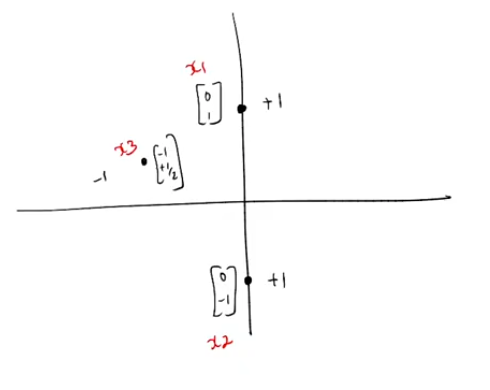

This dataset is linearly seperable. Any $w$ that points along the positive $x$ axis draws a deicision boundary perpendicular to it, that is, along the $y$ axis, which seperates the $+1$ and $-1$.

Let's walk through the algorithm. $w$ starts off as $\begin{bmatrix}
0 \\
0
\end{bmatrix}$, making an error on $x_3$.

It updates to $
\begin{bmatrix}
1 \\
-\frac{1}{2}
\end{bmatrix}
$

It now makes an error on $x_1$, getting updated to $
\begin{bmatrix}
1 \\
+\frac{1}{2}
\end{bmatrix}
$

It is now back to making an error on $x_2$ and will forever keep looping between the two values of $w$ above.

Well, clearly this is isn't working. But then again, the dataset is something of an edge case, because for the true $w$, points lie exactly on the decision boundary. It turns out that if we make a stronger assumption about the data, that there exists some margin $\gamma$ between the decision boundary and all points on either side, then the algorithm can be proved to converge.

## Proof of Convergence

1. The data is linearly seperable with $\gamma$-margin.

That is, $\exists \; w^* \in \mathbb{R}^d$ s.t: ${w^*}^{T} x_i \cdot y_i \geq \gamma \quad \forall i$ for some $\gamma > 0$

Without loss of generality, assume $\|w^*\|_2 = 1$. This is because the length of $w$ does not affect the decision boundary, which is always drawn perpendicular to $w$, through the origin.


Let $w_k$ be the weight vector after update $k$. Let a mistake occur at some point $x_i$ with label $y_i$. What we want to know is if $w_k$ is actually approaching the true $w$, $w^*$ we defined above, with each mistake it makes. to measure this, we take the dot product:

\begin{eqnarray}
w_{\ell+1}^T w^* &=& (w_{\ell} + x_iy_i)^T w^* \\
&=& w_{\ell}^T w^*  + x_i^T w^* \cdot y_i \\
&\ge& w_{\ell}^T w^* + \gamma \\
\end{eqnarray}

since $x_i^T w* \cdot y_i \ge \gamma$ by definition. At each mistake, since the quantity increases by $\gamma$, and as $w_0$ is the null vector, we can use this equation recursively to say that

$w_{\ell+1}^T w* \ge (\ell+1) \cdot \gamma$

Does this mean that each time a mistake is made, our estimate of $w$ grows closer to the true $w$? Not yet; it's entirely possible that this is due to the magnitude of $w_{\ell+1}$ just growing to cause this without $w_{\ell}$ actually converging to the direction of $w^*$. We must thus look for a bound on the magnitude of $w_{\ell+1}$, and then use the dot product of the unit vector along $w_{\ell+1}$ to make our argument.

Let's define $R$ such that, $\|x_i\|_2 \le R$ for all $x_i$, for $R > 0$. All points lie within a ball of finite radius $R$.

$w_{\ell+1} = w_{\ell} + x_i y_i$

$\|w_{\ell+1}\|^2 = \|w_{\ell}\|^2 + 2y_i(w_{\ell}^Tx_i) + \|x_i\|^2y_i^2$

$y_i^2 = 1$, $\|x_i\|^2 \le R^2$, and since a mistake occurred, $y_i(w_{\ell}^Tx_i) < 0$.

$\implies \|w_{\ell+1}\|^2 \le \|w_{\ell}\|^2 + R^2$

At each update, this grows by at most $R^2$. Since $w_0$ is the null vector,

$\implies \|w_{\ell+1}\|^2 \le  (\ell+1) \cdot R^2$

Now, we can say

\begin{eqnarray}
\frac{w_{\ell}}{\|w_{\ell}\|}^T w^* &\ge& \frac{\ell \cdot \gamma}{\|w_{\ell}\|} \\
&\ge& \sqrt{\ell} \cdot \frac{\gamma}{R} \\
\end{eqnarray}

Now we actually have proof that the estimate of $w$ is pointing closer and closer to the true $w$ with each mistake. Since ultimately this dot product cannot grow past 1, we have

\begin{eqnarray}
\sqrt{\ell} \cdot \frac{\gamma}{R} &\le& 1 \\
\sqrt{\ell} &\le \frac{R}{\gamma}&\\
\end{eqnarray}

$$\implies \boxed{\ell \le \frac{R^2}{\gamma^2}}$$

That is, the number of mistakes we can make is bounded by $\frac{R^2}{\gamma^2}$

QED.

## Quality

Although we are assured that after the algorithm coverges, all points are classified correctly, there are a variety of vectors $w$ that classify the dataset correctly, and some are clearly better than others:

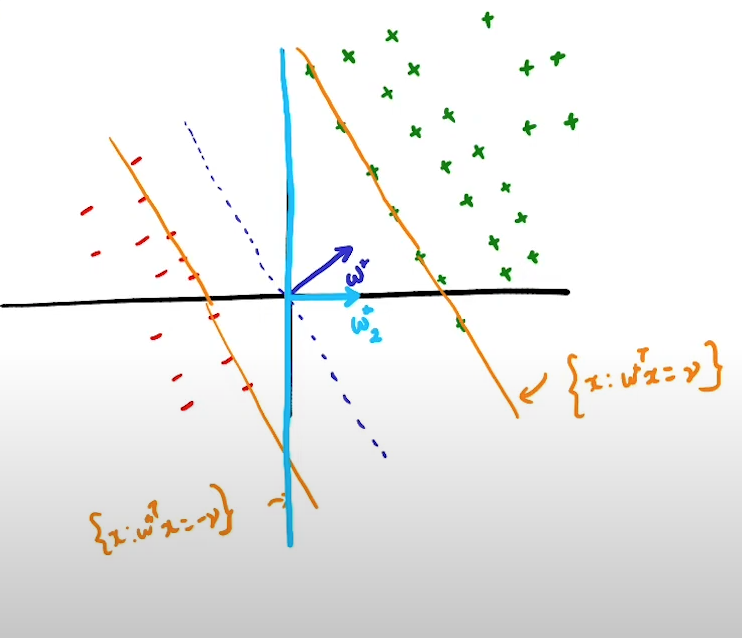

One natural way to quantify the goodness of $w$ is the magnitude of margin, $\gamma$ it uses. The blue line is worse because it has a small margin, and is thus likely very sensitive to perturbations in the data landing around that small margin.

We can thus formulate the problem as maximising that margin $\gamma$. However $\gamma$ isn't the margin, the perpendicular distance from the origin to line $w^Tx=\gamma$ is. For any $x$ on that line, component along $w$ is $$\frac{w^Tx}{\|w\|^2}\cdot w = \frac{\gamma}{\|w\|^2} \cdot w$$

which is of magnitude $\frac{\gamma}{\|w\|}$. Only when $\|w\| = 1$ $\gamma$ represents the size of the margin.

$$\max_{w, \gamma} \frac{2\gamma}{\|w\|}$$
$$\textit{s.t: } w^{T} x_i \cdot y_i \geq \gamma \quad \forall i $$

This is needlessly allowing both $\gamma$ and $w$ to vary, because if you fix a $w$, then the dataset and $w$ together detemine $\gamma$. Without loss of generality, we can assume $\gamma = 1$ and simplify. Thus, we have


$$\min_{w} \frac{1}{2}\cdot \|w\|$$

$$\textit{s.t } w^{T} x_i \cdot y_i \geq 1 \quad \forall i $$

This is the problem we will examine now.

# SVM


We encounter an arbitrary constrained optimization problem in the wild, as one does when walking in the woods on a Tuesday morning:

$$\min_w f(w)$$

$$\textit{s.t } g(w) \le 0$$

We have only ever done calculus without constraints, setting gradients to zero, or running gradient descent, and the constraints are bothersome. Thus, when the fairly godmother appears and tells us "Bruh, just define a function:
$$\mathcal{L}(w,\alpha) :=  f(w) + \alpha \cdot g(w)$$
and do
$$ \min_w \max_{\alpha \ge 0} \mathcal{L}(w, \alpha)$$
instead", we are overjoyed.

Why? Observe that if $g(w) > 0$, the thing just blows up to $\infty$ using $\alpha$, and if not, it gets $\alpha=0$ and we return to our minimization problem.

Note that $\alpha$ could just as easily be defined to be a vector of $\alpha_i$ for a series of constraints and the same argument holds.

Well, the first question that comes up is, can we safely swap the $\min$ and $\max$ ? The answer is yes, if $\mathcal{L}$ is convex, and this is called convex duality.

$$ \max_{\alpha \ge 0} \min_w \mathcal{L}(w, \alpha)$$
